# 03. Demand Forecasting Model Development
## Time Series Analysis & Multi-Step Forecasting

### Objectives:
1. Aggregate appointment data into a continuous daily time series (498 calendar days).
2. Examine temporal properties, weekly seasonality (7-day cycle), and autocorrelation.
3. Apply strictly chronological train-test splits (no future data leakage).
4. Compare three distinct modeling approaches:
   - **Seasonal Naive / Moving Average Baseline**
   - **XGBoost Regressor** (Tree-based model with calendar, lag, and rolling features)
   - **SARIMAX Model** (Autoregressive integrated moving average with weekly seasonality)
5. Evaluate models across MAE, RMSE, MAPE (handling zero/low values safely), sMAPE, and R².
6. Export the fitted forecasting pipeline to `models/demand_forecast_model.joblib`.


In [1]:
from pathlib import Path
import sys
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / 'src').exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

## Preprocessing
Data cleaning, duplicate handling, missingness preservation, and split boundaries precede fitted transformations.

## Feature engineering
Classification uses appointment, age, health, and calendar features. Demand forecasting uses calendar fields and strictly prior count lags and rolling summaries; weather is excluded.

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw_data, clean_dataset
from src.forecasting import (
    build_daily_time_series,
    engineer_forecasting_features,
    train_and_evaluate_forecasting,
    forecast_future_demand
)

sns.set_theme(style='whitegrid')
%matplotlib inline


### 1. Build Daily Continuous Series & Chronological Split

In [3]:
raw = load_raw_data('../data/raw.csv')
cleaned = clean_dataset(raw)
daily_all = build_daily_time_series(cleaned)

print(f"Daily series range: {daily_all['appointment_date'].min()} to {daily_all['appointment_date'].max()}")
print(f"Total days: {len(daily_all)}")
daily_all.head()


Daily series range: 2020-01-01 00:00:00 to 2021-05-12 00:00:00
Total days: 498


,appointment_date,appointment_count,average_temp_day,max_temp_day,average_rain_day,max_rain_day,storm_day_before
0,2020-01-01,25,21.106800,24.696000,0.093333,1.820833,1.000000
1,2020-01-02,33,20.813750,24.772414,0.170645,2.262500,0.878788
2,2020-01-03,18,20.991111,24.677778,0.208889,2.188889,0.833333
3,2020-01-04,16,20.415625,23.975000,0.053125,0.643750,1.000000
4,2020-01-05,15,21.152667,24.200000,0.403333,5.380000,1.000000


### 2. Autocorrelation & Seasonality Inspection

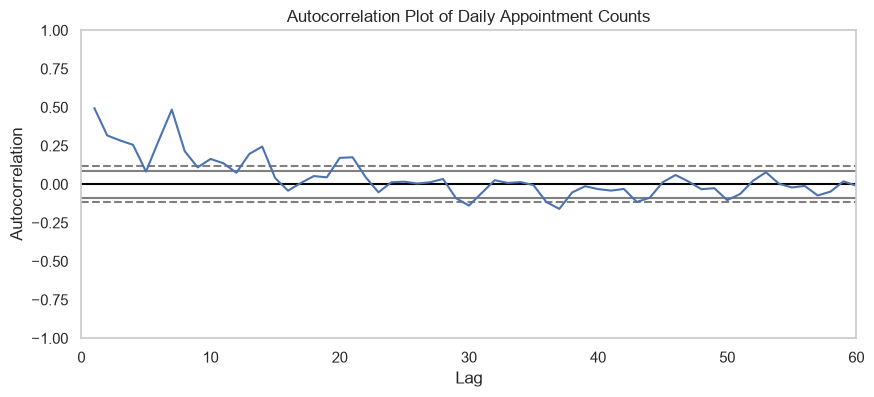

In [4]:
plt.figure(figsize=(10, 4))
pd.plotting.autocorrelation_plot(daily_all['appointment_count'])
plt.title('Autocorrelation Plot of Daily Appointment Counts')
plt.xlim(0, 60)
plt.show()


### 3. Chronological Model Training & Evaluation

In [5]:
results, best_model_name, best_model, test_eval_df = train_and_evaluate_forecasting(
    daily_all, test_ratio=0.20
)

# Tabulate every model under each evaluation protocol.
protocol_results = results.get('protocols', results)
metric_columns = [
    'mae', 'rmse', 'r2', 'wape', 'smape', 'mape', 'mape_volume_at_least_10'
]
results_rows = [
    {'protocol': protocol, 'model': model, **{
        metric: metrics[metric] for metric in metric_columns if metric in metrics
    }}
    for protocol, models in protocol_results.items()
    if isinstance(models, dict)
    for model, metrics in models.items()
    if isinstance(metrics, dict)
]
results_df = pd.DataFrame(results_rows)
results_df = results_df[['protocol', 'model'] + [
    metric for metric in metric_columns if metric in results_df.columns
]]

# Select and show the best model by recursive rolling-origin WAPE.
recursive_results = protocol_results['recursive_14_day_rolling_origin']
best_model_name = min(recursive_results, key=lambda model: recursive_results[model]['wape'])
best_model_metrics = recursive_results[best_model_name]
best_model_row = results_df[
    (results_df['protocol'] == 'recursive_14_day_rolling_origin')
    & (results_df['model'] == best_model_name)
]
print(f"Best model by recursive WAPE: {best_model_name} ({best_model_metrics['wape']:.2f}%)")
results_df

Best model by recursive WAPE: Random Forest Regressor (83.98%)


,protocol,model,mae,rmse,r2,wape,smape,mape,mape_volume_at_least_10
0,one_step_ahead,Seasonal Naive (Lag 7),180.083333,343.468066,-0.490609,93.317500,86.094683,3879.734165,89.328863
1,one_step_ahead,7-Day Moving Average,165.443452,263.346947,0.123710,85.731250,79.887194,2867.143616,182.933153
2,one_step_ahead,XGBoost Regressor,134.663223,253.056244,0.190857,69.781221,108.908322,1068.018275,70.795539
3,one_step_ahead,Random Forest Regressor,115.638089,238.180780,0.283189,59.922576,97.336440,731.236624,56.189848
4,one_step_ahead,SARIMAX,161.140031,266.383447,0.103386,83.501258,117.745142,3694.933101,130.310548
5,recursive_14_day_rolling_origin,Seasonal Naive (Lag 7),190.108108,354.581017,-0.577575,101.726781,86.704946,4401.070657,96.488815
6,recursive_14_day_rolling_origin,7-Day Moving Average,224.908249,363.722941,-0.659971,120.348324,93.656437,5039.662891,206.522955
7,recursive_14_day_rolling_origin,XGBoost Regressor,173.897297,296.433822,-0.102591,93.052382,128.368129,1969.417964,86.945030
8,recursive_14_day_rolling_origin,Random Forest Regressor,156.940541,280.929134,0.009732,83.978827,120.615343,1411.391792,75.060671
9,recursive_14_day_rolling_origin,SARIMAX,221.234299,317.976081,-0.268668,118.382395,127.718105,5648.418424,185.336228


### 4. Forecast Comparison on Chronological Test Set

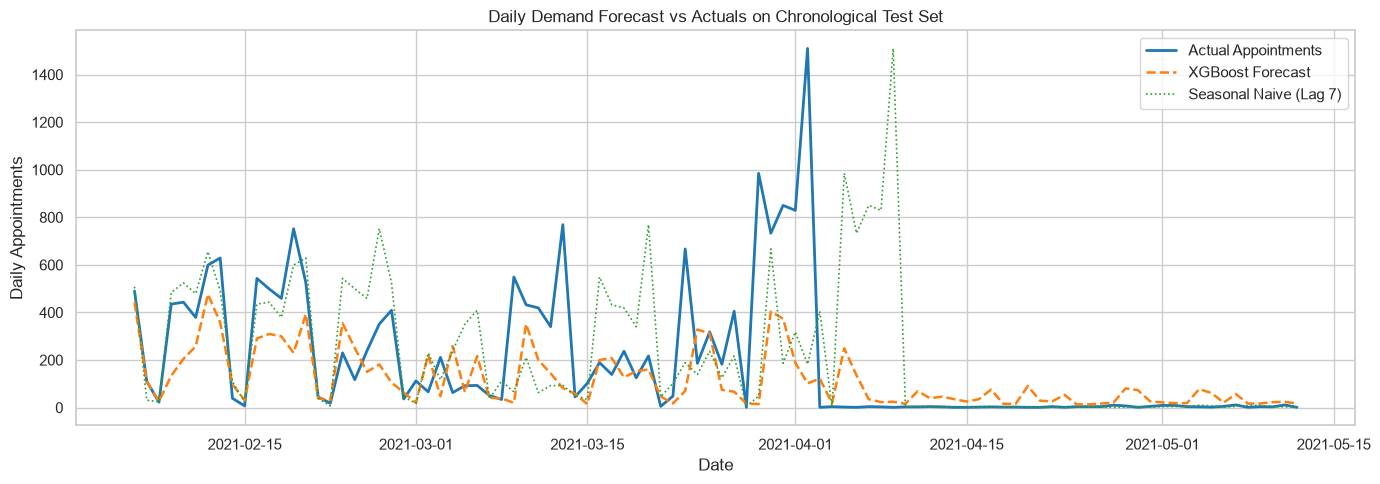

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(test_eval_df['appointment_date'], test_eval_df['appointment_count'], label='Actual Appointments', color='#1f77b4', lw=2)
plt.plot(test_eval_df['appointment_date'], test_eval_df['XGBoost'], label='XGBoost Forecast', color='#ff7f0e', lw=1.8, ls='--')
plt.plot(test_eval_df['appointment_date'], test_eval_df['Seasonal_Naive'], label='Seasonal Naive (Lag 7)', color='#2ca02c', lw=1.2, ls=':')
plt.title('Daily Demand Forecast vs Actuals on Chronological Test Set')
plt.xlabel('Date')
plt.ylabel('Daily Appointments')
plt.legend()
plt.tight_layout()
plt.show()


### 5. Multi-Step Recursive Forecasting Demonstration

In [7]:
artifact = {
    'model': best_model,
    'model_name': best_model_name,
    'metadata': {'metrics': best_model_metrics}
}

future_14d = forecast_future_demand(artifact, daily_all, horizon_days=14)
print("Projected Next 14 Days Demand:")
future_14d[['appointment_date', 'day_of_week', 'predicted_appointments']]

Projected Next 14 Days Demand:


,appointment_date,day_of_week,predicted_appointments
0,2021-05-13,Thursday,20
1,2021-05-14,Friday,15
2,2021-05-15,Saturday,18
3,2021-05-16,Sunday,20
4,2021-05-17,Monday,18
5,2021-05-18,Tuesday,18
6,2021-05-19,Wednesday,23
7,2021-05-20,Thursday,22
8,2021-05-21,Friday,23
9,2021-05-22,Saturday,30


### 6. Save Forecasting Artifact

Artifacts are written only by run_pipeline.py